# Cow lameness TCN — optimize for an Arduino Linux MPU

Colab workflow: load your **existing unoptimized checkpoint**, measure it, physically remove channels, fine-tune, fold BatchNorm, calibrate INT8, compare every stage, and export a deployable ONNX bundle.

Target: an **ARM64 Linux MPU**, such as the UNO Q's Qualcomm processor. ONNX Runtime CPU is a practical deployment choice for this PyTorch Conv1d model; this is not an MCU/Arduino-sketch export. Compression is optional on a Linux MPU, and INT8 is not guaranteed to be faster for such a small model. No NPU/GPU acceleration is assumed.

**No results are prefilled.** Run all cells in Colab with your Drive mounted. The attached notebooks do not contain the checkpoint weights or dataset. Tables, plots, model files and the deployment ZIP are produced from your real data when you run this notebook.

Input remains **keypoints**, not RGB: `(1, 102, 25)` float32. The pose detector is a separate model and is not optimized here. At 10 fps, 25 frames cover about 2.5 seconds. Preprocessing uses whole-video interpolation, orientation and scale; this is clip inference, not an equivalent causal streaming system.

## 0. Colab setup


In [1]:
%pip install --only-binary=:all: "onnx>=1.18,<2" "onnxruntime>=1.22,<2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 34.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 62.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnx]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import copy
import hashlib
import json
import platform
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import onnx
import onnxruntime as ort
from scipy.signal import savgol_filter
from scipy.special import expit
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from onnxruntime.quantization import (CalibrationDataReader, CalibrationMethod,
                                      QuantFormat, QuantType, quantize_static)
from onnxruntime.quantization.shape_inference import quant_pre_process
from IPython.display import display

print('torch:', torch.__version__, '| onnx:', onnx.__version__, '| ORT:', ort.__version__)

torch: 2.14.1+cu130 | onnx: 1.23.2 | ORT: 1.32.0


## 1. Config — your original paths are preserved
`OUT_DIR` is persistent in Drive. `EVAL_HOME=None` runs an explicitly **in-sample diagnostic** because your training notebook trains `final_model` on all videos in `HOME`. Splitting those videos now cannot undo the original training exposure.

For a real generalization comparison, set `EVAL_HOME` to unseen videos with `Normal/` and `Lame/` subfolders. Confirm these cows/source videos were absent from original training. Fine-tuning and calibration use only the training partition of `HOME`; validation chooses fine-tuning epochs and the final artifact. Neither uses the evaluation partition.

If multiple videos share a cow or source clip, provide a CSV with columns `name,group`, using names like `Lame/cow12` (no extension). Groups must be consistent across both roots. Without this map, each file is its own group, so animal-level independence cannot be established.

In [4]:
# --- paths (same input paths as your inference notebook) ------------------
HOME = Path('/content/drive/MyDrive/hackathon/Data/data')
MODEL_PATH = Path('/content/drive/MyDrive/hackathon/unoptimized-tcnn.pt')
OUT_DIR = Path('/content/drive/MyDrive/hackathon/outputs/tcn_optimization')
EVAL_HOME = None       # e.g. Path('/content/drive/MyDrive/hackathon/Data/unseen')
GROUP_MAP_PATH = None  # optional Path to CSV: name,group

# --- preprocessing: MUST match your checkpoint ---------------------------
CLASSES = {'Normal': 0, 'Lame': 1}
HAS_HEADER = True
DROP_COLS = ['x_full', 'y_full']
CSV_SUFFIXES = {'.csv', '.tsv', '.txt'}
K = 20
TAIL, WITHERS, NOSE = 6, 7, 4
CONF_THR = 0.3
SMOOTH_WIN, SMOOTH_ORDER = 5, 2
W, TEST_STRIDE, TOPK = 25, 5, None
THRESHOLD = 0.5
HIDDEN, KERNEL, DROPOUT = 32, 5, 0.3

# --- fixed before looking at evaluation results --------------------------
SEED = 0
PRUNE_FRACTION = 0.25          # 32 -> 24 channels in each convolution
FT_EPOCHS = 15
WINDOWS_PER_EPOCH, BATCH = 400, 32
FT_LR, WD, JITTER = 1e-4, 1e-2, 0.01
CALIB_WINDOWS = 256
MAX_F1_DROP = 0.02            # absolute validation metric tolerance
MAX_RECALL_DROP = 0.02
BENCH_WARMUP, BENCH_RUNS = 30, 300

OUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(1)
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)
assert 0 <= PRUNE_FRACTION < 1
assert FT_EPOCHS >= 1 and CALIB_WINDOWS >= 1
print('Fine-tuning device:', DEVICE)

Fine-tuning device: cuda


## 2. Loading and preprocessing — unchanged from your inference notebook

In [5]:
def load_video(path):
    df = pd.read_csv(path, sep=None, engine="python",       # sep=None auto-detects tab/comma
                     header=0 if HAS_HEADER else None)
    if HAS_HEADER:
        df.columns = df.columns.astype(str).str.strip()
        df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])   # drop x_full / y_full
    df = df.iloc[:, :5]
    df.columns = ["image", "keypoint", "x", "y", "score"]

    # Frame number = last run of digits in the image name ("000012.jpg" -> 12)
    frame = df["image"].astype(str).str.extract(r"(\d+)(?=\D*$)")[0].astype(int).values
    frame = frame - frame.min()

    # Frames/keypoints with no row stay NaN and get filled in preprocessing
    arr = np.full((frame.max() + 1, K, 3), np.nan)
    arr[frame, df["keypoint"].astype(int).values] = df[["x", "y", "score"]].values
    return arr

In [6]:
def preprocess(arr, name=""):
    xy = arr[..., :2].copy()
    score = np.nan_to_num(arr[..., 2])            # missing rows get score 0

    # 2a. Treat low-confidence keypoints as missing, then fill the gaps by
    #     interpolating each keypoint's x and y over time. No frames are added;
    #     this only fills values inside the video's own time axis.
    xy[score < CONF_THR] = np.nan
    for k in range(K):
        for c in range(2):
            xy[:, k, c] = pd.Series(xy[:, k, c]).interpolate(limit_direction="both").values
    if np.isnan(xy).any():                         # a keypoint was never confident
        print(f"  warning: {name}: a keypoint never exceeded the confidence threshold")
        xy = np.nan_to_num(xy)

    # 2b. Light temporal smoothing (window kept short so the gait is not blurred)
    if len(xy) >= SMOOTH_WIN:
        xy = savgol_filter(xy, SMOOTH_WIN, SMOOTH_ORDER, axis=0)

    # 2c. Make every cow face right, so videos are comparable
    if np.mean(xy[:, NOSE, 0] - xy[:, TAIL, 0]) < 0:
        xy[..., 0] *= -1

    # 2d. Remove camera position and distance:
    #     origin = midpoint of tail base and top of back (per frame),
    #     scale  = mean distance between those two points over the whole video.
    root = (xy[:, TAIL] + xy[:, WITHERS]) / 2
    body_len = np.linalg.norm(xy[:, WITHERS] - xy[:, TAIL], axis=-1).mean() + 1e-6
    xy = (xy - root[:, None]) / body_len

    # 2e. Velocities: joint motion relative to the body, and the body's own
    #     speed (in body lengths per frame), which the origin shift removed.
    vel = np.diff(xy, axis=0, prepend=xy[:1])
    root_vel = np.diff(root / body_len, axis=0, prepend=root[:1] / body_len)

    # 2f. Stack channels: 40 positions + 40 velocities + 20 scores + 2 body velocity = 102
    feats = np.concatenate([xy.reshape(len(xy), -1),
                            vel.reshape(len(xy), -1),
                            score,
                            root_vel], axis=1)
    return feats.astype(np.float32)

## 3. Load the unoptimized model — same architecture and checkpoint format

In [7]:
class SmallTCN(nn.Module):
    def __init__(self, in_ch, hidden=HIDDEN, k=KERNEL, dropout=DROPOUT):
        super().__init__()
        p = k // 2
        self.net = nn.Sequential(
            nn.BatchNorm1d(in_ch),                                   # standardize input channels
            nn.Conv1d(in_ch, hidden, k, padding=p),
            nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, k, padding=p, stride=2),       # downsample in time
            nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, k, padding=p, stride=2),
            nn.BatchNorm1d(hidden), nn.ReLU(),
        )
        self.head = nn.Linear(2 * hidden, 1)

    def forward(self, x):                       # x: (batch, channels, time)
        h = self.net(x)                         # (batch, hidden, time')
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)   # global average + max pooling
        return self.head(h).squeeze(1)          # one logit per window

In [8]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'Checkpoint not found: {MODEL_PATH}')
# Load only a trusted checkpoint. Do not disable weights_only for unknown files.
ckpt = torch.load(MODEL_PATH, map_location='cpu', weights_only=True)
assert int(ckpt['window']) == W, 'Window length must match training.'
assert int(ckpt['in_ch']) == 5 * K + 2 == 102
baseline = SmallTCN(ckpt['in_ch'])
baseline.load_state_dict(ckpt['state_dict'], strict=True)
baseline.eval()
IN_CH = int(ckpt['in_ch'])
print('Loaded:', MODEL_PATH)
print('Parameters:', sum(p.numel() for p in baseline.parameters()))
print('Checkpoint KiB:', MODEL_PATH.stat().st_size / 1024)

Loaded: /content/drive/MyDrive/hackathon/unoptimized-tcnn.pt
Parameters: 27117
Checkpoint KiB: 116.7724609375


## 4. Data partitions and audit
All eligible videos are used, rather than the inference notebook's random six per class. The split is deterministic and group-aware. The diagnostic default is approximately 60% train / 20% validation / 20% evaluation. With an external evaluation root, `HOME` is approximately 80% train / 20% validation.

The notebook stops if any partition lacks a class or if there are too few independent groups. Identical file contents across partitions are rejected. The saved manifest records every video, group and content hash. Validation in `HOME` remains exposed to original model training; only a truly unseen evaluation root can supply independent final metrics.

In [9]:
group_map = None
if GROUP_MAP_PATH is not None:
    gm = pd.read_csv(GROUP_MAP_PATH, dtype=str)
    assert {'name', 'group'} <= set(gm.columns)
    assert not gm['name'].duplicated().any() and gm['group'].notna().all()
    group_map = dict(zip(gm['name'], gm['group']))
else:
    print('GROUPING: one file per group; same-cow independence is NOT verified.')

def build_records(home):
    records = []
    for cls, label in CLASSES.items():
        folder = home / cls
        if not folder.is_dir():
            raise FileNotFoundError(folder)
        for p in sorted(folder.rglob('*')):
            if not p.is_file() or p.suffix.lower() not in CSV_SUFFIXES:
                continue
            name = str(p.relative_to(home).with_suffix(''))
            feats = preprocess(load_video(p), name=p.name)
            if len(feats) < W:
                print('Skipped short video:', name, len(feats))
                continue
            assert feats.shape[1] == IN_CH and np.isfinite(feats).all(), name
            if group_map is not None and name not in group_map:
                raise ValueError(f'Missing group mapping: {name}')
            records.append(dict(name=name, path=str(p), feats=feats, label=label,
                                group=group_map[name] if group_map is not None else name,
                                sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
    assert records and len({r['name'] for r in records}) == len(records), 'Empty/duplicate video names'
    return records

def split_records(records, n_splits, seed):
    y = np.array([r['label'] for r in records])
    g = np.array([r['group'] for r in records])
    count = min(len(set(g[y == c])) for c in (0, 1))
    n = min(n_splits, count)
    if n < 2:
        raise ValueError('Need at least two independent groups per class to split.')
    cv = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    a, b = next(cv.split(np.zeros(len(y)), y, g))
    return [records[i] for i in a], [records[i] for i in b]

all_records = build_records(HOME)
if EVAL_HOME is None:
    pool, test_records = split_records(all_records, 5, SEED)
    train_records, val_records = split_records(pool, 4, SEED + 1)
    EVAL_SCOPE = 'IN-SAMPLE diagnostic: checkpoint may have trained on every evaluation video'
else:
    train_records, val_records = split_records(all_records, 5, SEED)
    test_records = build_records(Path(EVAL_HOME))
    EVAL_SCOPE = 'External evaluation: independence from original training must be confirmed by owner'
parts = {'train': train_records, 'validation': val_records, 'evaluation': test_records}
for name, rr in parts.items():
    assert {r['label'] for r in rr} == {0, 1}, f'{name} must contain both classes'
    print(name, len(rr), 'videos;', sum(r['label'] for r in rr), 'Lame')
for a, b in [('train', 'validation'), ('train', 'evaluation'), ('validation', 'evaluation')]:
    for key in ('group', 'sha256'):
        assert not ({r[key] for r in parts[a]} & {r[key] for r in parts[b]}), f'{key} overlap: {a}/{b}'
manifest = pd.DataFrame([{**{k: r[k] for k in ('name','path','label','group','sha256')}, 'split': split}
                         for split, rr in parts.items() for r in rr])
manifest.to_csv(OUT_DIR / 'split_manifest.csv', index=False)
print(EVAL_SCOPE)

GROUPING: one file per group; same-cow independence is NOT verified.
Skipped short video: Normal/N (18) 19
Skipped short video: Normal/N (23) 14
train 34 videos; 12 Lame
validation 12 videos; 5 Lame
evaluation 11 videos; 5 Lame
IN-SAMPLE diagnostic: checkpoint may have trained on every evaluation video


## 5. Shared evaluation and benchmarking
Every stage uses the same videos, threshold, stride, final-window inclusion and mean/top-k aggregation. Report accuracy, precision, lame recall, F1, AUC, confusion matrix, per-video probability changes, ONNX file size, parameter count and batch-1 latency.

Latency is a warmed, single-thread **Colab CPU model-only** measurement (p50/p95); it excludes loading, CSV preprocessing, pose detection and runtime startup. It is not Arduino latency or peak RAM. Every stage uses the same ONNX Runtime optimization settings, which may already fold BatchNorm internally. Model-file bytes are not total application RAM.

Export checks PyTorch/ONNX parity on real windows before measuring. Float ONNX export keeps BatchNorm in the graph where possible; dropout is inactive in evaluation mode.

In [10]:
def video_windows(feats):
    starts = list(range(0, len(feats) - W + 1, TEST_STRIDE))
    if starts[-1] != len(feats) - W:
        starts.append(len(feats) - W)
    for s in starts:
        yield np.ascontiguousarray(feats[s:s+W].T[None], dtype=np.float32)

def probabilities(run, records):
    result = []
    for r in records:
        probs = np.array([float(expit(np.asarray(run(x)).reshape(-1)[0]))
                          for x in video_windows(r['feats'])])
        result.append(float(np.sort(probs)[-TOPK:].mean() if TOPK else probs.mean()))
    return np.array(result)

def metrics(records, p):
    y = np.array([r['label'] for r in records])
    pred = (p >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, p), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def make_session(path):
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = 1
    opts.inter_op_num_threads = 1
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(str(path), sess_options=opts, providers=['CPUExecutionProvider'])

probe = next(video_windows(train_records[0]['feats']))
parity_probes = [next(video_windows(r['feats'])) for r in train_records[:8]]

def export_float(model, name):
    model = copy.deepcopy(model).cpu().eval()
    path = OUT_DIR / f'{name}.onnx'
    torch.onnx.export(model, torch.from_numpy(probe), str(path),
                      input_names=['features'], output_names=['logits'],
                      opset_version=17, do_constant_folding=False, dynamo=False)
    onnx.checker.check_model(onnx.load(str(path)))
    session = make_session(path)
    errors = []
    with torch.no_grad():
        for x in parity_probes:
            expected = model(torch.from_numpy(x)).numpy()
            actual = session.run(None, {'features': x})[0]
            np.testing.assert_allclose(actual, expected, rtol=1e-4, atol=1e-5)
            errors.append(float(np.max(np.abs(actual - expected))))
    print(name, 'export parity max logit error:', max(errors))
    return path

rows, predictions, stage_paths = [], {}, {}
def evaluate_stage(name, path, parameter_count):
    session = make_session(path)
    run = lambda x: session.run(None, {'features': x})[0]
    for _ in range(BENCH_WARMUP): run(probe)
    durations = []
    for _ in range(BENCH_RUNS):
        start = time.perf_counter_ns()
        run(probe)
        durations.append((time.perf_counter_ns() - start) / 1e6)
    for split, records in [('validation', val_records), ('evaluation', test_records)]:
        p = probabilities(run, records)
        predictions[(name, split)] = p
        ref = predictions.get(('00_original', split), p)
        row = dict(stage=name, split=split, **metrics(records, p),
                   parameters=parameter_count, onnx_KiB=path.stat().st_size / 1024,
                   cpu_p50_ms=float(np.median(durations)), cpu_p95_ms=float(np.percentile(durations, 95)),
                   mean_probability_shift=float(np.mean(np.abs(p-ref))),
                   changed_decisions=int(np.sum((p >= THRESHOLD) != (ref >= THRESHOLD))))
        rows.append(row)
        pd.DataFrame({'video':[r['name'] for r in records], 'label':[r['label'] for r in records],
                      'prob_lame':p, 'pred':(p >= THRESHOLD).astype(int)}).to_csv(
                          OUT_DIR / f'{name}_{split}_predictions.csv', index=False)
    stage_paths[name] = path
    table = pd.DataFrame(rows)
    table.to_csv(OUT_DIR / 'stage_metrics.csv', index=False)
    display(table[table.stage == name].round(5))
    return session

def nparams(model): return sum(p.numel() for p in model.parameters())

## 6. Stage 0 — unoptimized FP32 baseline

In [11]:
baseline_path = export_float(baseline, '00_original')
_ = evaluate_stage('00_original', baseline_path, nparams(baseline))

/tmp/ipykernel_1361/3475941201.py:38: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.from_numpy(probe), str(path),


00_original export parity max logit error: 1.430511474609375e-06


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,parameters,onnx_KiB,cpu_p50_ms,cpu_p95_ms,mean_probability_shift,changed_decisions
0,00_original,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,5,27117,110.53711,0.05588,0.109,0.0,0
1,00_original,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,5,27117,110.53711,0.05588,0.109,0.0,0


## 7. Stage 1 — real structured channel pruning, before fine-tuning
Remove 25% of convolution channels by default. Rank each layer's filters by L1 magnitude after accounting for the following BatchNorm scale. Copy retained weights into a **smaller dense network**, slice the next convolution's input channels, and update both halves of the mean+max head.

This reduces tensor dimensions; simply setting weights to zero would not reliably accelerate normal dense CPU kernels. The input feature count stays 102. This is a fixed heuristic, not an evaluation-driven pruning search.

In [12]:
def prune_channels(model, fraction):
    src = copy.deepcopy(model).cpu().eval()
    old_h = src.net[1].out_channels
    new_h = max(1, round(old_h * (1 - fraction)))
    dst = SmallTCN(IN_CH, hidden=new_h).eval()
    dst.net[0].load_state_dict(src.net[0].state_dict())
    previous = torch.arange(IN_CH)
    kept = []
    with torch.no_grad():
        for ci, bi in [(1, 2), (5, 6), (9, 10)]:
            conv, bn = src.net[ci], src.net[bi]
            scale = bn.weight.abs() / torch.sqrt(bn.running_var + bn.eps)
            importance = conv.weight.abs().sum(dim=(1, 2)) * scale
            idx = torch.topk(importance, new_h).indices.sort().values
            dst.net[ci].weight.copy_(conv.weight[idx][:, previous])
            dst.net[ci].bias.copy_(conv.bias[idx])
            for key in ('weight', 'bias', 'running_mean', 'running_var'):
                getattr(dst.net[bi], key).copy_(getattr(bn, key)[idx])
            dst.net[bi].num_batches_tracked.copy_(bn.num_batches_tracked)
            previous = idx
            kept.append(idx.tolist())
        head_idx = torch.cat([previous, previous + old_h])
        dst.head.weight.copy_(src.head.weight[:, head_idx])
        dst.head.bias.copy_(src.head.bias)
    return dst, kept

pruned, kept_channels = prune_channels(baseline, PRUNE_FRACTION)
print('Hidden channels:', HIDDEN, '->', pruned.net[1].out_channels)
print('Parameters:', nparams(baseline), '->', nparams(pruned))
(OUT_DIR / 'kept_channels.json').write_text(json.dumps(kept_channels, indent=2))
pruned_path = export_float(pruned, '01_pruned_before_ft')
_ = evaluate_stage('01_pruned_before_ft', pruned_path, nparams(pruned))

Hidden channels: 32 -> 24
Parameters: 27117 -> 18469
01_pruned_before_ft export parity max logit error: 1.1920928955078125e-06


/tmp/ipykernel_1361/3475941201.py:38: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.from_numpy(probe), str(path),


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,parameters,onnx_KiB,cpu_p50_ms,cpu_p95_ms,mean_probability_shift,changed_decisions
2,01_pruned_before_ft,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,5,18469,76.53516,0.07678,0.10931,0.05076,0
3,01_pruned_before_ft,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,5,18469,76.53516,0.07678,0.10931,0.06252,0


## 8. Stage 2 — fine-tune the pruned model, then evaluate
Reuse your random windows, jitter, AdamW and class-weighted BCE. Only training records supply gradients. Choose the epoch using validation F1, then AUC as a tie-breaker; keep epoch 0 if fine-tuning never improves it. The threshold remains fixed. A smaller learning rate and 15 epochs are the defaults.

The learning curve uses validation data only. Evaluation is run on the selected checkpoint after fine-tuning, not used for early stopping.

epoch 01: loss=0.0903, val F1=1.0000, AUC=1.0000
epoch 02: loss=0.0878, val F1=1.0000, AUC=1.0000
epoch 03: loss=0.0643, val F1=1.0000, AUC=1.0000
epoch 04: loss=0.0834, val F1=1.0000, AUC=1.0000
epoch 05: loss=0.0522, val F1=1.0000, AUC=1.0000
epoch 06: loss=0.0922, val F1=1.0000, AUC=1.0000
epoch 07: loss=0.0761, val F1=1.0000, AUC=1.0000
epoch 08: loss=0.0963, val F1=1.0000, AUC=1.0000
epoch 09: loss=0.0593, val F1=1.0000, AUC=1.0000
epoch 10: loss=0.0376, val F1=1.0000, AUC=1.0000
epoch 11: loss=0.0524, val F1=1.0000, AUC=1.0000
epoch 12: loss=0.0352, val F1=1.0000, AUC=1.0000
epoch 13: loss=0.0419, val F1=1.0000, AUC=1.0000
epoch 14: loss=0.0272, val F1=1.0000, AUC=1.0000
epoch 15: loss=0.0395, val F1=1.0000, AUC=1.0000
Selected epoch: 0


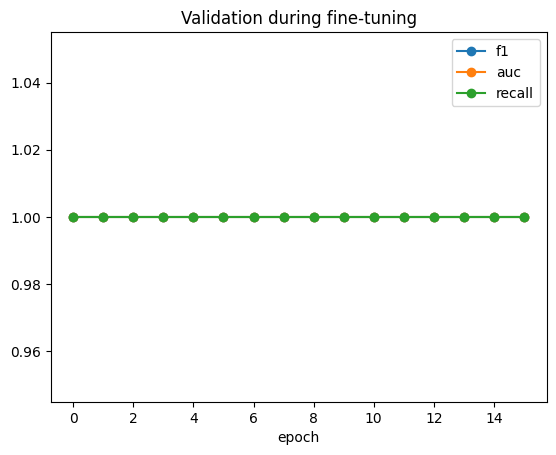

/tmp/ipykernel_1361/3475941201.py:38: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.from_numpy(probe), str(path),


02_pruned_finetuned export parity max logit error: 1.1920928955078125e-06


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,parameters,onnx_KiB,cpu_p50_ms,cpu_p95_ms,mean_probability_shift,changed_decisions
4,02_pruned_finetuned,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,5,18469,76.53516,0.08149,0.11179,0.05076,0
5,02_pruned_finetuned,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,5,18469,76.53516,0.08149,0.11179,0.06252,0


In [13]:
class TrainWindows(Dataset):
    def __init__(self, records, n_samples=WINDOWS_PER_EPOCH):
        self.records, self.n = records, n_samples
    def __len__(self): return self.n
    def __getitem__(self, _):
        r = self.records[np.random.randint(len(self.records))]
        f = r['feats']
        s = np.random.randint(0, len(f) - W + 1)
        noise = np.random.normal(0, JITTER, (W, f.shape[1])).astype(np.float32)
        return torch.from_numpy((f[s:s+W] + noise).T.copy()), torch.tensor(float(r['label']))

@torch.no_grad()
def torch_val(model):
    model.eval()
    dev = next(model.parameters()).device
    def run(x): return model(torch.from_numpy(x).to(dev)).cpu().numpy()
    return metrics(val_records, probabilities(run, val_records))

set_seed(SEED)
ft = copy.deepcopy(pruned).to(DEVICE)
initial = torch_val(ft)
best_key = (initial['f1'], initial['auc'])
best_state = copy.deepcopy(ft.cpu().state_dict())
ft.to(DEVICE)
best_epoch = 0
history = [dict(epoch=0, loss=np.nan, **initial)]
optimizer = torch.optim.AdamW(ft.parameters(), lr=FT_LR, weight_decay=WD)
n_pos = sum(r['label'] for r in train_records)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(
    (len(train_records) - n_pos) / n_pos, device=DEVICE))
loader = DataLoader(TrainWindows(train_records), batch_size=BATCH, num_workers=0)
for epoch in range(1, FT_EPOCHS + 1):
    ft.train()
    loss_sum, count = 0., 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(ft(x), y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(y)
        count += len(y)
    m = torch_val(ft)
    key = (m['f1'], m['auc'])
    history.append(dict(epoch=epoch, loss=loss_sum/count, **m))
    if key > best_key:
        best_key, best_epoch = key, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in ft.state_dict().items()}
    print(f"epoch {epoch:02d}: loss={loss_sum/count:.4f}, val F1={m['f1']:.4f}, AUC={m['auc']:.4f}")
ft.cpu().load_state_dict(best_state)
ft.eval()
print('Selected epoch:', best_epoch)
history_df = pd.DataFrame(history)
history_df.to_csv(OUT_DIR / 'fine_tuning_history.csv', index=False)
history_df.plot(x='epoch', y=['f1', 'auc', 'recall'], marker='o', title='Validation during fine-tuning')
plt.show()
torch.save({'state_dict': ft.state_dict(), 'in_ch':IN_CH, 'window':W,
            'hidden':ft.net[1].out_channels, 'kernel':KERNEL, 'dropout':DROPOUT},
           OUT_DIR / 'pruned_finetuned.pt')
ft_path = export_float(ft, '02_pruned_finetuned')
_ = evaluate_stage('02_pruned_finetuned', ft_path, nparams(ft))

## 9. Stage 3 — fold Conv → BatchNorm and remove dropout
Fold each post-convolution BatchNorm into its convolution in evaluation mode, with a numerical equivalence check. Keep the **input BatchNorm**: moving it through a padded convolution naively changes edge values. Dropout becomes identity. This stage needs no fine-tuning.

An ONNX Runtime session may already perform the same fusion, so a latency improvement at this step is not assumed.

In [14]:
fused = copy.deepcopy(ft).eval()
for ci, bi in [(1, 2), (5, 6), (9, 10)]:
    fused.net[ci] = torch.nn.utils.fusion.fuse_conv_bn_eval(fused.net[ci], fused.net[bi])
    fused.net[bi] = nn.Identity()
for i, layer in enumerate(fused.net):
    if isinstance(layer, nn.Dropout): fused.net[i] = nn.Identity()
with torch.no_grad():
    for x in parity_probes:
        torch.testing.assert_close(fused(torch.from_numpy(x)), ft(torch.from_numpy(x)),
                                   rtol=1e-4, atol=1e-5)
fused_path = export_float(fused, '03_pruned_fused')
_ = evaluate_stage('03_pruned_fused', fused_path, nparams(fused))

03_pruned_fused export parity max logit error: 9.5367431640625e-07


/tmp/ipykernel_1361/3475941201.py:38: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.from_numpy(probe), str(path),


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,parameters,onnx_KiB,cpu_p50_ms,cpu_p95_ms,mean_probability_shift,changed_decisions
6,03_pruned_fused,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,5,18325,74.35352,0.04905,0.07251,0.05076,0
7,03_pruned_fused,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,5,18325,74.35352,0.04905,0.07251,0.06252,0


## 10. Stage 4 — calibrated static INT8 (QDQ), then evaluate
Calibrate on deterministic, unaugmented windows from **training only**, sampling across both classes and videos. Per-channel INT8 weights and INT8 activations are requested for Conv and Gemm/MatMul. Static quantization fits this convolutional model better than quantizing only the final Linear layer dynamically.

The ONNX interface remains float32. Quantize/dequantize operators handle internal conversions; normalization and some pooling/other operators can remain float. This is a **mixed graph with INT8 compute candidates**, not an all-integer MCU model. Runtime kernel support determines actual acceleration. No additional training is performed after this post-training quantization; its measured impact is reported separately. If it fails the validation guard, final selection falls back to FP32.

In [15]:
rng = np.random.default_rng(SEED)
by_class = {c:[r for r in train_records if r['label'] == c] for c in (0, 1)}
calibration = []
for i in range(CALIB_WINDOWS):
    rr = by_class[i % 2]
    r = rr[int(rng.integers(len(rr)))]
    s = int(rng.integers(len(r['feats']) - W + 1))
    calibration.append(np.ascontiguousarray(r['feats'][s:s+W].T[None], dtype=np.float32))

class Reader(CalibrationDataReader):
    def __init__(self, windows): self.windows = windows; self.rewind()
    def get_next(self):
        x = next(self.iterator, None)
        return None if x is None else {'features': x}
    def rewind(self): self.iterator = iter(self.windows)

prepared_path = OUT_DIR / 'quantization_prepared.onnx'
# Shape inference only: avoid serializing host-specific runtime optimizations.
quant_pre_process(str(fused_path), str(prepared_path), skip_optimization=True)
int8_path = OUT_DIR / '04_pruned_int8.onnx'
quantize_static(str(prepared_path), str(int8_path), Reader(calibration),
                quant_format=QuantFormat.QDQ, activation_type=QuantType.QInt8,
                weight_type=QuantType.QInt8, per_channel=True,
                calibrate_method=CalibrationMethod.MinMax,
                op_types_to_quantize=['Conv', 'Gemm', 'MatMul'])
graph = onnx.load(str(int8_path))
onnx.checker.check_model(graph)
int8_tensors = [t.name for t in graph.graph.initializer if t.data_type == onnx.TensorProto.INT8]
assert int8_tensors, 'No INT8 tensors were created.'
assert any(n.op_type == 'QuantizeLinear' for n in graph.graph.node)
print('INT8 initializer count:', len(int8_tensors))
print('Graph operator counts:', pd.Series([n.op_type for n in graph.graph.node]).value_counts().to_dict())
_ = evaluate_stage('04_pruned_int8', int8_path, nparams(fused))

INT8 initializer count: 16
Graph operator counts: {'DequantizeLinear': 16, 'QuantizeLinear': 8, 'Conv': 3, 'Relu': 3, 'Constant': 1, 'BatchNormalization': 1, 'ReduceMean': 1, 'ReduceMax': 1, 'Concat': 1, 'Gemm': 1, 'Squeeze': 1}


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,parameters,onnx_KiB,cpu_p50_ms,cpu_p95_ms,mean_probability_shift,changed_decisions
8,04_pruned_int8,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,5,18325,29.33691,0.05204,0.0863,0.05073,0
9,04_pruned_int8,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,5,18325,29.33691,0.05204,0.0863,0.06264,0


## 11. Compare performance at every stage
Metric deltas are relative to the unoptimized model on the **same split**. Positive latency speedup and size reduction are beneficial; negative F1/recall deltas indicate a loss. Small evaluation sets produce noisy metrics. Use the confusion counts as well as headline scores.

IN-SAMPLE diagnostic: checkpoint may have trained on every evaluation video


,stage,split,accuracy,precision,recall,f1,auc,tn,fp,fn,...,cpu_p95_ms,mean_probability_shift,changed_decisions,delta_accuracy,delta_precision,delta_recall,delta_f1,delta_auc,size_reduction_pct,cpu_speedup
0,00_original,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,...,0.10900,0.00000,0,0.0,0.0,0.0,0.0,0.0,0.00000,1.00000
1,00_original,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,...,0.10900,0.00000,0,0.0,0.0,0.0,0.0,0.0,0.00000,1.00000
2,01_pruned_before_ft,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,...,0.10931,0.05076,0,0.0,0.0,0.0,0.0,0.0,30.76067,0.72774
3,01_pruned_before_ft,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,...,0.10931,0.06252,0,0.0,0.0,0.0,0.0,0.0,30.76067,0.72774
4,02_pruned_finetuned,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,...,0.11179,0.05076,0,0.0,0.0,0.0,0.0,0.0,30.76067,0.68568
5,02_pruned_finetuned,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,...,0.11179,0.06252,0,0.0,0.0,0.0,0.0,0.0,30.76067,0.68568
6,03_pruned_fused,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,...,0.07251,0.05076,0,0.0,0.0,0.0,0.0,0.0,32.73434,1.13918
7,03_pruned_fused,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,...,0.07251,0.06252,0,0.0,0.0,0.0,0.0,0.0,32.73434,1.13918
8,04_pruned_int8,validation,1.0,1.0,1.0,1.0,1.0,7,0,0,...,0.08630,0.05073,0,0.0,0.0,0.0,0.0,0.0,73.45967,1.07374
9,04_pruned_int8,evaluation,1.0,1.0,1.0,1.0,1.0,6,0,0,...,0.08630,0.06264,0,0.0,0.0,0.0,0.0,0.0,73.45967,1.07374


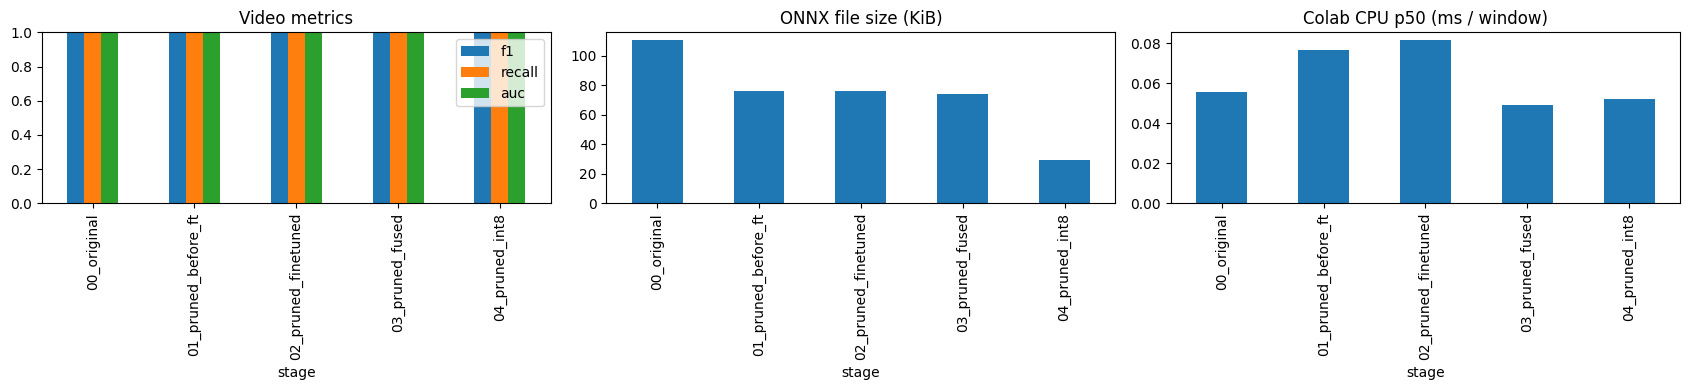

In [16]:
comparison = pd.DataFrame(rows)
for split in ('validation', 'evaluation'):
    mask = comparison['split'] == split
    ref = comparison[mask & (comparison.stage == '00_original')].iloc[0]
    for metric in ('accuracy', 'precision', 'recall', 'f1', 'auc'):
        comparison.loc[mask, f'delta_{metric}'] = comparison.loc[mask, metric] - ref[metric]
    comparison.loc[mask, 'size_reduction_pct'] = 100*(1-comparison.loc[mask, 'onnx_KiB']/ref.onnx_KiB)
    comparison.loc[mask, 'cpu_speedup'] = ref.cpu_p50_ms/comparison.loc[mask, 'cpu_p50_ms']
comparison.to_csv(OUT_DIR / 'comparison.csv', index=False)
print(EVAL_SCOPE)
display(comparison.round(5))
plot = comparison[comparison.split == 'evaluation'].set_index('stage')
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
plot[['f1', 'recall', 'auc']].plot.bar(ax=axes[0], ylim=(0, 1), title='Video metrics')
plot['onnx_KiB'].plot.bar(ax=axes[1], title='ONNX file size (KiB)')
plot['cpu_p50_ms'].plot.bar(ax=axes[2], title='Colab CPU p50 (ms / window)')
fig.tight_layout()
fig.savefig(OUT_DIR / 'comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Choose and export the final model
Choose the **smallest ONNX file** among the original FP32, fine-tuned/fused FP32 and INT8 candidates that satisfy the validation F1 and recall tolerances. This is a size-first policy, not a claim of best on-board speed. Evaluation scores do not enter selection. Keep the original as a guaranteed fallback. The INT8 candidate is always saved even if it is rejected.

`arduino_model.onnx` is the selected model, not necessarily INT8. The bundle includes all three deployment candidates so that you can compare latency on the actual board, the identical preprocessing implementation, model metadata, a numerical test vector, a command-line CSV inference script and benchmark script. No PyTorch is needed on the MPU.

In [17]:
val = comparison[comparison.split == 'validation'].set_index('stage')
reference = val.loc['00_original']
candidates = ['00_original', '03_pruned_fused', '04_pruned_int8']
eligible = [s for s in candidates
            if val.loc[s, 'f1'] >= reference.f1 - MAX_F1_DROP
            and val.loc[s, 'recall'] >= reference.recall - MAX_RECALL_DROP]
selected = min(eligible, key=lambda s: val.loc[s, 'onnx_KiB'])
print('Selected:', selected, '| validation-eligible:', eligible)
print('Selection policy: smallest file within validation F1/recall tolerance.')
BUNDLE = OUT_DIR / 'arduino_mpu_bundle'
BUNDLE.mkdir(exist_ok=True)
shutil.copy2(stage_paths[selected], BUNDLE / 'arduino_model.onnx')
for name in candidates:
    shutil.copy2(stage_paths[name], BUNDLE / f'{name}.onnx')
metadata = dict(selected_stage=selected, evaluation_scope=EVAL_SCOPE,
    input_name='features', output_name='logits', input_shape=[1, IN_CH, W],
    input_dtype='float32', output='one logit per window; apply sigmoid before aggregation',
    threshold=THRESHOLD, classes=CLASSES, window=W, stride=TEST_STRIDE, topk=TOPK,
    preprocessing=dict(K=K, TAIL=TAIL, WITHERS=WITHERS, NOSE=NOSE, CONF_THR=CONF_THR,
                       SMOOTH_WIN=SMOOTH_WIN, SMOOTH_ORDER=SMOOTH_ORDER,
                       HAS_HEADER=HAS_HEADER, DROP_COLS=DROP_COLS),
    seed=SEED, pruning_fraction=PRUNE_FRACTION, fine_tuning_best_epoch=best_epoch,
    max_validation_f1_drop=MAX_F1_DROP, max_validation_recall_drop=MAX_RECALL_DROP,
    calibration_windows=CALIB_WINDOWS, target='ARM64 Linux MPU / ONNX Runtime CPU',
    source_checkpoint_sha256=hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
    model_sha256=hashlib.sha256((BUNDLE/'arduino_model.onnx').read_bytes()).hexdigest(),
    versions=dict(torch=torch.__version__, onnx=onnx.__version__, onnxruntime=ort.__version__,
                  numpy=np.__version__, python=platform.python_version()),
    benchmark_host=platform.platform())
(BUNDLE / 'model_metadata.json').write_text(json.dumps(metadata, indent=2))
np.save(BUNDLE / 'test_input.npy', probe)
np.save(BUNDLE / 'test_logits.npy', make_session(BUNDLE / 'arduino_model.onnx').run(None, {'features':probe})[0])
# Source is embedded literally below, preserving original preprocessing.

Selected: 04_pruned_int8 | validation-eligible: ['00_original', '03_pruned_fused', '04_pruned_int8']
Selection policy: smallest file within validation F1/recall tolerance.


In [18]:
preprocessing_source = 'def load_video(path):\n    df = pd.read_csv(path, sep=None, engine="python",       # sep=None auto-detects tab/comma\n                     header=0 if HAS_HEADER else None)\n    if HAS_HEADER:\n        df.columns = df.columns.astype(str).str.strip()\n        df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])   # drop x_full / y_full\n    df = df.iloc[:, :5]\n    df.columns = ["image", "keypoint", "x", "y", "score"]\n\n    # Frame number = last run of digits in the image name ("000012.jpg" -> 12)\n    frame = df["image"].astype(str).str.extract(r"(\\d+)(?=\\D*$)")[0].astype(int).values\n    frame = frame - frame.min()\n\n    # Frames/keypoints with no row stay NaN and get filled in preprocessing\n    arr = np.full((frame.max() + 1, K, 3), np.nan)\n    arr[frame, df["keypoint"].astype(int).values] = df[["x", "y", "score"]].values\n    return arr\n\ndef preprocess(arr, name=""):\n    xy = arr[..., :2].copy()\n    score = np.nan_to_num(arr[..., 2])            # missing rows get score 0\n\n    # 2a. Treat low-confidence keypoints as missing, then fill the gaps by\n    #     interpolating each keypoint\'s x and y over time. No frames are added;\n    #     this only fills values inside the video\'s own time axis.\n    xy[score < CONF_THR] = np.nan\n    for k in range(K):\n        for c in range(2):\n            xy[:, k, c] = pd.Series(xy[:, k, c]).interpolate(limit_direction="both").values\n    if np.isnan(xy).any():                         # a keypoint was never confident\n        print(f"  warning: {name}: a keypoint never exceeded the confidence threshold")\n        xy = np.nan_to_num(xy)\n\n    # 2b. Light temporal smoothing (window kept short so the gait is not blurred)\n    if len(xy) >= SMOOTH_WIN:\n        xy = savgol_filter(xy, SMOOTH_WIN, SMOOTH_ORDER, axis=0)\n\n    # 2c. Make every cow face right, so videos are comparable\n    if np.mean(xy[:, NOSE, 0] - xy[:, TAIL, 0]) < 0:\n        xy[..., 0] *= -1\n\n    # 2d. Remove camera position and distance:\n    #     origin = midpoint of tail base and top of back (per frame),\n    #     scale  = mean distance between those two points over the whole video.\n    root = (xy[:, TAIL] + xy[:, WITHERS]) / 2\n    body_len = np.linalg.norm(xy[:, WITHERS] - xy[:, TAIL], axis=-1).mean() + 1e-6\n    xy = (xy - root[:, None]) / body_len\n\n    # 2e. Velocities: joint motion relative to the body, and the body\'s own\n    #     speed (in body lengths per frame), which the origin shift removed.\n    vel = np.diff(xy, axis=0, prepend=xy[:1])\n    root_vel = np.diff(root / body_len, axis=0, prepend=root[:1] / body_len)\n\n    # 2f. Stack channels: 40 positions + 40 velocities + 20 scores + 2 body velocity = 102\n    feats = np.concatenate([xy.reshape(len(xy), -1),\n                            vel.reshape(len(xy), -1),\n                            score,\n                            root_vel], axis=1)\n    return feats.astype(np.float32)'
runner_prefix = """import argparse, json
from pathlib import Path
import numpy as np
import pandas as pd
import onnxruntime as ort
from scipy.signal import savgol_filter
from scipy.special import expit
ROOT = Path(__file__).resolve().parent
META = json.loads((ROOT / 'model_metadata.json').read_text())
globals().update(META['preprocessing'])
W, TEST_STRIDE, TOPK = META['window'], META['stride'], META['topk']
"""
runner_suffix = """
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('csv', type=Path)
    parser.add_argument('--model', type=Path, default=ROOT / 'arduino_model.onnx')
    args = parser.parse_args()
    f = preprocess(load_video(args.csv), args.csv.name)
    if len(f) < W: raise ValueError(f'Need at least {W} frames; received {len(f)}')
    if not np.isfinite(f).all(): raise ValueError('Non-finite features')
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = opts.inter_op_num_threads = 1
    session = ort.InferenceSession(str(args.model), sess_options=opts, providers=['CPUExecutionProvider'])
    starts = list(range(0, len(f)-W+1, TEST_STRIDE))
    if starts[-1] != len(f)-W: starts.append(len(f)-W)
    probs = []
    for s in starts:
        x = np.ascontiguousarray(f[s:s+W].T[None], dtype=np.float32)
        probs.append(float(expit(session.run(None, {'features':x})[0].reshape(-1)[0])))
    p = float(np.sort(probs)[-TOPK:].mean() if TOPK else np.mean(probs))
    print(json.dumps({'prob_lame':p, 'prediction':'Lame' if p >= META['threshold'] else 'Normal',
                      'windows':len(starts)}))
if __name__ == '__main__': main()
"""
(BUNDLE / 'infer_csv.py').write_text(runner_prefix + preprocessing_source + runner_suffix)

4437

In [19]:
benchmark_source = """import argparse, json, platform, time
from pathlib import Path
import numpy as np
import onnxruntime as ort
ROOT = Path(__file__).resolve().parent
parser = argparse.ArgumentParser()
parser.add_argument('--threads', type=int, default=1)
parser.add_argument('--runs', type=int, default=1000)
args = parser.parse_args()
assert args.threads >= 1 and args.runs >= 1
x = np.load(ROOT / 'test_input.npy')
rows = []
for path in sorted(ROOT.glob('*.onnx')):
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = args.threads
    opts.inter_op_num_threads = 1
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    session = ort.InferenceSession(str(path), sess_options=opts, providers=['CPUExecutionProvider'])
    def run(): return session.run(None, {'features':x})[0]
    if path.name == 'arduino_model.onnx':
        np.testing.assert_allclose(run(), np.load(ROOT / 'test_logits.npy'), rtol=1e-3, atol=1e-3)
    for _ in range(50): run()
    samples = []
    for _ in range(args.runs):
        start = time.perf_counter_ns()
        run()
        samples.append((time.perf_counter_ns()-start)/1e6)
    rows.append(dict(model=path.name, KiB=path.stat().st_size/1024,
                     p50_ms=float(np.median(samples)), p95_ms=float(np.percentile(samples,95))))
print(json.dumps(dict(host=platform.platform(), machine=platform.machine(),
                      runtime=ort.__version__, threads=args.threads, results=rows), indent=2))
"""
(BUNDLE / 'benchmark_mpu.py').write_text(benchmark_source)
(BUNDLE / 'requirements.txt').write_text('onnxruntime==1.20.1\nnumpy>=1.26,<3\npandas>=2,<3\nscipy>=1.11,<2\n')
readme = f"""# Cow lameness — Linux MPU deployment
Selected model: {selected}
Evaluation scope: {EVAL_SCOPE}

This bundle runs on a Linux ARM64 MPU (e.g. UNO Q), not the microcontroller.
Use a Python 3.11/3.12 virtual environment with a compatible ONNX Runtime wheel.
No Arduino IDE sketch, PyTorch, GPU or NPU is required.

On the board, in the extracted bundle directory:

    python3 -m venv .venv
    . .venv/bin/activate
    python -m pip install -r requirements.txt
    python benchmark_mpu.py --threads 1
    python infer_csv.py /path/to/keypoints.csv

If the pinned runtime has no wheel for the board's Python/OS, use a supported
ARM64 runtime/Python combination and rerun the test-vector and benchmark checks.
The bundle contains an INT8 candidate and FP32 fallbacks. Measure each on the MPU;
Colab timing is not transferable. No runtime memory limit is inferred from file size.

Input: float32 [1,102,25]. Output: logit, converted to sigmoid probability.
Aggregate window probabilities (not logits), then threshold at {THRESHOLD}.
The metadata records preprocessing, aggregation and selection settings.
The CSV reader and preprocessing are copied from the original inference notebook.
A camera needs a separate pose estimator producing the same 20 indexed keypoints
and coordinate/confidence conventions at 10 fps. The preprocessing uses the entire
clip, so live causal processing requires a separate validated redesign.

The included test_input.npy is one real training-data feature window.
This is a research/hackathon classification score, not a calibrated pain probability.
"""
(BUNDLE / 'README.md').write_text(readme)
for name in ['comparison.csv', 'fine_tuning_history.csv', 'split_manifest.csv', 'comparison.png']:
    shutil.copy2(OUT_DIR/name, BUNDLE/name)
# Syntax-check generated scripts and verify the packaged runtime output.
import ast
for path in BUNDLE.glob('*.py'): ast.parse(path.read_text())
packaged = make_session(BUNDLE / 'arduino_model.onnx')
np.testing.assert_allclose(packaged.run(None, {'features':probe})[0],
                           np.load(BUNDLE/'test_logits.npy'), rtol=1e-5, atol=1e-6)
zip_path = shutil.make_archive(str(OUT_DIR/'arduino_mpu_bundle'), 'zip', root_dir=BUNDLE)
print('Final model:', BUNDLE/'arduino_model.onnx')
print('Deployment ZIP:', zip_path)
print('Comparison:', OUT_DIR/'comparison.csv')

Final model: /content/drive/MyDrive/hackathon/outputs/tcn_optimization/arduino_mpu_bundle/arduino_model.onnx
Deployment ZIP: /content/drive/MyDrive/hackathon/outputs/tcn_optimization/arduino_mpu_bundle.zip
Comparison: /content/drive/MyDrive/hackathon/outputs/tcn_optimization/comparison.csv


## 13. Download (optional)
Everything is already saved under your Drive `hackathon/outputs/tcn_optimization` folder. Run this cell to download the complete deployment bundle to your computer.

In [20]:
from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References and interpretation
- [Arduino UNO Q hardware](https://docs.arduino.cc/hardware/uno-q/): Linux MPU versus MCU.
- [ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html): calibration, static QDQ and INT8 trade-offs.
- [PyTorch Conv/BatchNorm fusion](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.fusion.fuse_conv_bn_eval.html).

The input model is already small. If compression reduces recall materially, keep FP32 or lower `PRUNE_FRACTION` and run a new experiment. Choose hyperparameters using validation only; repeated inspection and adjustment against evaluation scores invalidates an independent final test. QAT or distillation can be a subsequent experiment if post-training INT8 loses too much accuracy; neither is assumed necessary here. Do not label these results as cross-validation: this notebook compares transformations of one already-trained checkpoint.